# CFAR vs Deep Learning — the comparison

**The one-line answer.** *At finding targets in interference the network wins; at placing them
precisely CFAR wins; and the network runs at roughly GO/SO-CFAR cost, far cheaper than OS.*

**What this notebook is.** The result, organised by question. `cnn_development_log.ipynb` is the
chronological record — every experiment in the order it was run, including six retractions. This is
the distilled comparison: the headline numbers, where each method wins, why, and what is wrong with
the comparison.

**Everything here is on `bench2_test`**, the held-out split, read **once** on 19 Aug 2026 against a
protocol pre-registered on 17 Aug (`docs/test_preregistration.md`). No number below was chosen after
seeing it.

**How to read it.**
1. §1 the protocol, and the check that it held
2. §2 the headline
3. §3–§5 where DL wins, where CFAR wins, where they tie — each with the mechanism
4. §6 the absolute check against theory
5. §7 computational cost
6. §8 the scorecard
7. **§9 problems, caveats and odd results** — read this before quoting anything above it

> ⚠️ **§9 is not an appendix.** Several headline numbers carry a bias whose direction is known, and
> at least one result is statistically significant but physically meaningless. Quoting §2 without
> §9 would overstate the case.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DL = ROOT / "results" / "dl"
CT = ROOT / "results" / "cfar_test"

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#898781", "#e1e0d9"
DLC, CFARC, WIN, LOSS, TIE = "#8172b3", "#4c72b0", "#2e7d32", "#c62828", "#8a8a8a"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
                     "axes.grid": True, "grid.alpha": 0.55, "figure.dpi": 120})

CONDS = ["clutter_edge", "mixed", "isolated", "masking", "multi", "unresolved", "clutter"]

T1 = pd.read_csv(DL / "bootstrap_frozen_ep021_test_tol1.csv").set_index("condition")
T2 = pd.read_csv(DL / "bootstrap_frozen_ep021_test_tol3.csv").set_index("condition")
LOC = pd.read_csv(DL / "localization_frozen_ep021_test.csv")
PFA = pd.read_csv(DL / "measured_pfa_frozen_ep021_test_tol1.csv")
RT = pd.read_csv(DL / "runtime_cost_frozen_ep021_test.csv")
SNRC = pd.read_csv(DL / "pd_vs_snr_frozen_ep021.csv")
SNRS = pd.read_csv(DL / "pd_vs_snr_frozen_ep021_summary.csv")

ALPHA = 0.05 / len(T1)
print(f"bench2_test — {int(T1.n_frames.sum()):,} scored frames, {int(T1.targets.sum()):,} targets, "
      f"{len(T1)} conditions")
print(f"Bonferroni alpha = {ALPHA:.4f}")

bench2_test — 2,800 scored frames, 6,163 targets, 7 conditions
Bonferroni alpha = 0.0071


---
## 1 · The protocol — and the check that it held

**The comparison is only meaningful if both methods are given exactly the same job.** Five
constraints, each enforced in code rather than by convention:

| | |
|---|---|
| **Same operating point** | matched **measured** Pfa 1e-4, swept **per condition**. Never design Pfa — clutter drives achieved rates 60–125× above design, by different factors for each method |
| **Same post-processing** | both call the *same* `all_peaks()` with the same `nms_size=5`. Divergent post-processing is structurally impossible |
| **Same scored region** | CFAR cannot test within one window half-width of the border, so the network is scored on that same interior mask — identical Pfa denominators |
| **Same metric** | one-to-one matching in a ±1-bin gate, through `src/eval` for both |
| **Same uncertainty treatment** | DL = 8 seeds; CFAR gets a paired frame bootstrap so *both* sides carry sampling error; Bonferroni across 7 conditions |

**The receptive field is matched on purpose.** `TinyCNN` sees **21×9** cells, measured by backprop
— exactly the CFAR window. The network is not allowed more context than the classical detector.

### Did the operating points actually match?
Every comparison below assumes they did. This is the check.

In [2]:
r = PFA.pivot(index="condition", columns="method", values="ratio_to_target")
worst = float(np.abs(r.to_numpy() - 1).max())
print(f"measured Pfa / 1e-4 target — worst deviation across all method-condition cells: "
      f"{worst * 100:.1f}%")
display(r.round(3))
print("1.00 = exactly on target. All within 2%, so the arms really were placed at the same")
print("false-alarm rate and every Pd difference below is like-for-like.")

measured Pfa / 1e-4 target — worst deviation across all method-condition cells: 1.9%


method,CA,DL,GO,OS,SO
condition,,,,,
clutter,0.983,0.998,0.994,1.017,0.991
clutter_edge,0.994,1.000,0.998,0.990,0.983
isolated,1.007,0.999,0.996,1.011,0.990
masking,0.987,0.998,1.000,0.987,1.013
mixed,1.004,1.002,1.000,0.993,0.991
multi,0.981,1.001,0.991,1.015,0.992
noise,0.993,1.001,1.003,1.010,1.001
unresolved,1.007,0.998,0.998,0.988,1.005


1.00 = exactly on target. All within 2%, so the arms really were placed at the same
false-alarm rate and every Pd difference below is like-for-like.


**✅ The protocol held.** Every method on every condition sits within **2%** of the 1e-4 target.
Nothing below is explained by a mismatched operating point.

---
## 2 · The headline — Pd per condition

DL against **the best of CA/GO/OS/SO on each condition**, at the matched operating point.

In [3]:
h = pd.DataFrame({
    "best CFAR": T1.cfar_method,
    "CFAR Pd": T1.cfar_pd, "DL Pd": T1.dl_pd,
    "diff": T1["diff"], "95% CI": [f"[{lo:+.3f}, {hi:+.3f}]" for lo, hi in zip(T1.ci_lo, T1.ci_hi)],
    "p": T1.p_boot,
    "verdict": ["DL WINS" if (s and d > 0) else ("CFAR WINS" if (s and d < 0) else "tie")
                for s, d in zip(T1["sig (Bonf)"], T1["diff"])],
}).loc[CONDS]

# The verdict column is mechanical -- it only reads the p-value. Two rows need a caveat carried
# WITH the table, because tables get lifted out of context and both would otherwise be misread.
NOTE = {"unresolved": "significant but NOT a win -- both at the ~0.5 physics cap (S5/S9.3)",
        "isolated":   "win is real but UNEXPLAINED -- CFAR should be optimal here (S9.6)",
        "clutter":    "tie, and both methods miss ~83% of targets"}
h["caveat"] = [NOTE.get(c, "") for c in h.index]
display(h.round(4))
n_win = (h.verdict == "DL WINS").sum()
print(f"DL wins {n_win} of {len(h)} after Bonferroni; CFAR wins "
      f"{(h.verdict == 'CFAR WINS').sum()}; {(h.verdict == 'tie').sum()} tie.")
print()
print("But 'wins 6 of 7' is the wrong summary to carry away -- see the caveat column, and S9.")

,best CFAR,CFAR Pd,DL Pd,diff,95% CI,p,verdict,caveat
condition,,,,,,,,
clutter_edge,OS,0.4492,0.7508,0.3017,"[+0.267, +0.337]",0.000,DL WINS,
mixed,GO,0.4260,0.5291,0.1031,"[+0.082, +0.124]",0.000,DL WINS,
isolated,CA,0.6750,0.7331,0.0581,"[+0.036, +0.082]",0.000,DL WINS,win is real but UNEXPLAINED -- CFAR should be ...
masking,OS,0.6225,0.6736,0.0511,"[+0.037, +0.065]",0.000,DL WINS,
multi,CA,0.6871,0.7316,0.0446,"[+0.034, +0.056]",0.000,DL WINS,
unresolved,CA,0.4638,0.4756,0.0119,"[+0.004, +0.020]",0.001,DL WINS,significant but NOT a win -- both at the ~0.5 ...
clutter,GO,0.1714,0.1691,-0.0023,"[-0.019, +0.012]",0.793,tie,"tie, and both methods miss ~83% of targets"


DL wins 6 of 7 after Bonferroni; CFAR wins 0; 1 tie.

But 'wins 6 of 7' is the wrong summary to carry away -- see the caveat column, and S9.


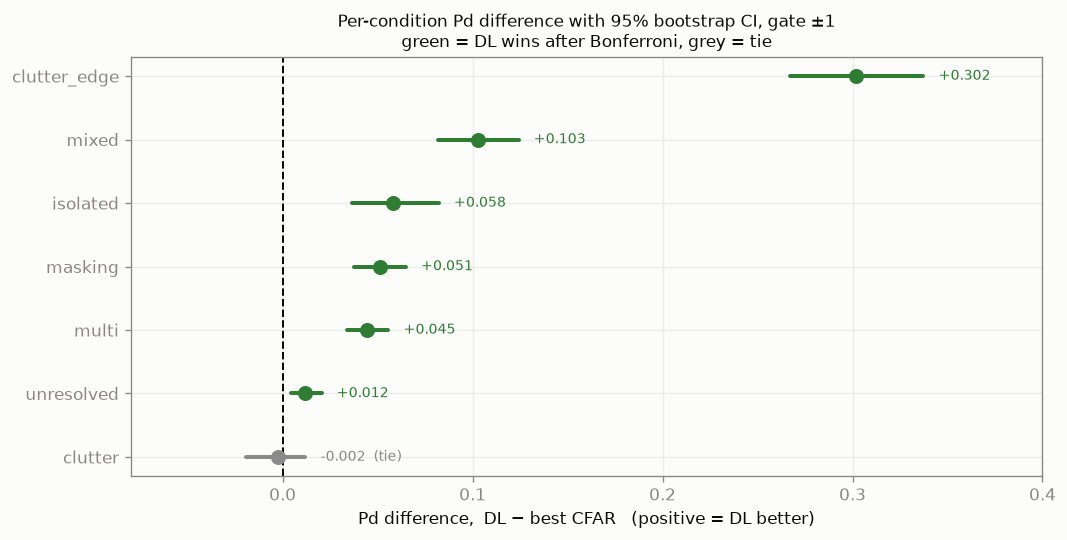

In [4]:
# Forest plot: the DIFFERENCE with its confidence interval. Shows significance directly --
# an interval clear of the dashed line is a win, one crossing it is a tie.
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(CONDS))[::-1]
for yi, c in zip(y, CONDS):
    d, lo, hi = T1.loc[c, "diff"], T1.loc[c, "ci_lo"], T1.loc[c, "ci_hi"]
    sig = T1.loc[c, "sig (Bonf)"]
    col = WIN if (sig and d > 0) else (LOSS if (sig and d < 0) else TIE)
    ax.plot([lo, hi], [yi, yi], color=col, lw=2.4, solid_capstyle="round")
    ax.plot(d, yi, "o", color=col, ms=8, zorder=5)
    ax.text(hi + 0.008, yi, f"{d:+.3f}" + ("" if sig else "  (tie)"), va="center",
            fontsize=8.5, color=col)
ax.axvline(0, color=INK, ls="--", lw=1.2)
ax.set_yticks(y); ax.set_yticklabels(CONDS)
ax.set_xlabel("Pd difference,  DL − best CFAR   (positive = DL better)")
ax.set_title("Per-condition Pd difference with 95% bootstrap CI, gate ±1\n"
             "green = DL wins after Bonferroni, grey = tie", fontsize=10)
ax.set_xlim(-0.08, 0.40)
plt.tight_layout(); plt.show()

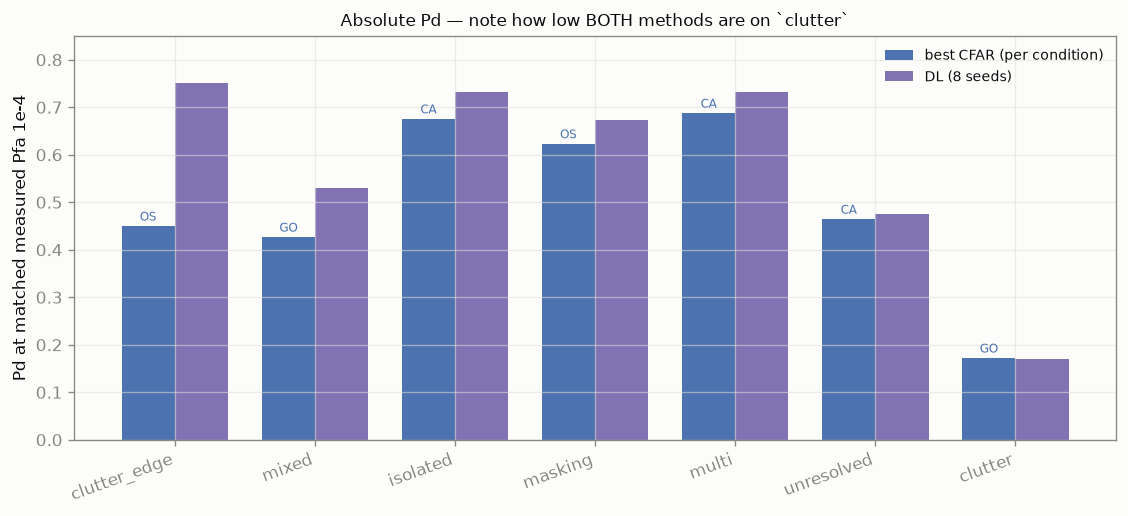

In [5]:
# Absolute Pd side by side -- the forest plot shows the difference, this shows the level.
fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(CONDS)); w = 0.38
ax.bar(x - w/2, T1.loc[CONDS, "cfar_pd"], w, color=CFARC, label="best CFAR (per condition)")
ax.bar(x + w/2, T1.loc[CONDS, "dl_pd"], w, color=DLC, label="DL (8 seeds)")
for xi, c in zip(x, CONDS):
    ax.text(xi - w/2, T1.loc[c, "cfar_pd"] + 0.012, T1.loc[c, "cfar_method"],
            ha="center", fontsize=7, color=CFARC)
ax.set_xticks(x); ax.set_xticklabels(CONDS, rotation=20, ha="right")
ax.set_ylabel("Pd at matched measured Pfa 1e-4"); ax.set_ylim(0, 0.85)
ax.set_title("Absolute Pd — note how low BOTH methods are on `clutter`", fontsize=10)
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

### What the headline says

**DL wins 6 of 7 conditions and loses none.** The margins span two orders of magnitude, from
`clutter_edge` **+0.302** down to `unresolved` **+0.012** — and that spread matters more than the
count, because the small ones are not all real wins in any useful sense (§5, §9).

**`clutter` is a tie, and both methods are terrible there** — CFAR 0.171, DL 0.169. Roughly five
targets in six are missed by *both*. It is the hardest condition in the benchmark and neither
approach solves it.

---
## 3 · Where DL wins — and why

Ordered by margin. The mechanism matters more than the number: a win we cannot explain is a win we
should not trust.

In [6]:
w = T1.loc[[c for c in CONDS if T1.loc[c, "sig (Bonf)"] and T1.loc[c, "diff"] > 0]]
w = w.sort_values("diff", ascending=False)
display(pd.DataFrame({"best CFAR": w.cfar_method, "CFAR Pd": w.cfar_pd, "DL Pd": w.dl_pd,
                      "gain": w["diff"], "relative": w["diff"] / w.cfar_pd,
                      "p": w.p_boot}).round(4))
print("`relative` = gain as a fraction of the CFAR baseline -- clutter_edge is a 68% improvement,")
print("unresolved a 2.6% one. Same 'win' column, very different claims.")

,best CFAR,CFAR Pd,DL Pd,gain,relative,p
condition,,,,,,
clutter_edge,OS,0.4492,0.7508,0.3017,0.6717,0.000
mixed,GO,0.4260,0.5291,0.1031,0.2420,0.000
isolated,CA,0.6750,0.7331,0.0581,0.0861,0.000
masking,OS,0.6225,0.6736,0.0511,0.0821,0.000
multi,CA,0.6871,0.7316,0.0446,0.0649,0.000
unresolved,CA,0.4638,0.4756,0.0119,0.0256,0.001


`relative` = gain as a fraction of the CFAR baseline -- clutter_edge is a 68% improvement,
unresolved a 2.6% one. Same 'win' column, very different claims.


### `clutter_edge` +0.302 — the big one, and the most defensible

**The setup.** The target sits in clean noise, but the CFAR reference window *reaches into* a
clutter ridge. The window therefore averages clutter the target never touched, the estimated noise
level is far too high, and the threshold is set way above where it should be.

**Why CFAR loses.** This is the classical failure mode CFAR variants were invented for, and OS —
the variant designed for exactly this — *is* the best classical method here (0.449 vs CA 0.397,
GO 0.415). It still loses by 0.302. Rank-ordering rejects *outliers*; it cannot fix a reference
window where a large *fraction* of cells is contaminated.

**Why DL wins.** The network is not required to treat its receptive field as a homogeneous noise
sample. It can learn that a bright ridge on one side is *structure* rather than noise, and weight it
differently. That is precisely the freedom a fixed statistical estimator does not have.

**This is the single most important result in the project** — the largest margin, on the condition
the literature (RadCNN's S3) names as where a CNN should win.

⚠️ *Caveat carried from Milestone 22:* only ~66% of this stratum's frames have a window that
genuinely straddles the ridge; the other 34% are diluted. The margin was re-checked against the
true-edge subset and survives (dev log Open/O1).

### `mixed` +0.103 and `masking` +0.051 — interference, same root cause

Both are multi-target scenes where a strong return sits near a weak one. The strong target lands
*inside the reference window* of the weak one, inflating its noise estimate and raising its
threshold — self-masking. CFAR's only defence is the guard region, which is sized for the mainlobe,
not for a second target a few bins away.

The network has no such constraint: it can recognise a two-peak pattern as two targets rather than
as one target plus elevated noise.

### `multi` +0.045 and `isolated` +0.058 — smaller, and less about interference

`multi` is many well-separated targets — mild mutual interference, so a mild win.

**`isolated` is the interesting one.** It is a single target in homogeneous noise: exactly the case
CFAR is *optimal* for, and where the corpus predicts a tie. On `bench2_val` it *was* a tie
(+0.019, p = 0.030, short of the corrected threshold). On the test split, with twice the frames, it
becomes a clear win (+0.058, p < 0.001).

**The honest reading:** the pre-registration flagged `isolated` as genuinely uncertain in advance,
so this is not a post-hoc discovery — but the delta *tripled*, which is more than tighter error bars
explain, and we do not have a mechanism for a 0.058 gain in homogeneous noise. **Treat it as
unexplained** (§9).

---
## 4 · Where CFAR wins — localization, decisively

Detection asks *did you find it*. Localization asks *did you put it in the right place*. These are
different questions and they have different winners.

In [7]:
for gate in (1, 3):
    d = LOC[(LOC.gate == gate) & (LOC.group == "ALL")].set_index("method")
    dl, cf = d.loc["DL"], d.drop("DL")
    br, bd = cf.dr_bins.idxmin(), cf.dv_bins.idxmin()
    print(f"gate +/-{gate} pooled:  DL range {dl.dr_bins:.3f} vs {cf.dr_bins.min():.3f} ({br}) "
          f"= {dl.dr_bins / cf.dr_bins.min():.2f}x   |   "
          f"DL Doppler {dl.dv_bins:.3f} vs {cf.dv_bins.min():.3f} ({bd}) "
          f"= {dl.dv_bins / cf.dv_bins.min():.2f}x")
    display(d[["pd", "dr_bins", "dr_bins_se", "dv_bins", "dv_bins_se"]].round(4))

gate +/-1 pooled:  DL range 0.475 vs 0.198 (OS) = 2.40x   |   DL Doppler 0.382 vs 0.100 (OS) = 3.83x


,pd,dr_bins,dr_bins_se,dv_bins,dv_bins_se
method,,,,,
CA,0.4861,0.2109,NaN,0.1051,NaN
GO,0.4970,0.2129,NaN,0.1198,NaN
OS,0.4868,0.1980,NaN,0.0997,NaN
SO,0.2551,0.2036,NaN,0.1177,NaN
DL,0.5915,0.4755,0.0207,0.3817,0.0256


gate +/-3 pooled:  DL range 0.491 vs 0.242 (OS) = 2.03x   |   DL Doppler 0.392 vs 0.135 (OS) = 2.91x


,pd,dr_bins,dr_bins_se,dv_bins,dv_bins_se
method,,,,,
CA,0.4972,0.2546,NaN,0.1381,NaN
GO,0.5080,0.2546,NaN,0.1501,NaN
OS,0.4976,0.2423,NaN,0.1347,NaN
SO,0.2624,0.2430,NaN,0.1793,NaN
DL,0.5981,0.4912,0.0212,0.3925,0.0257


,dl_range,cfar_range,range_x,dl_dopp,cfar_dopp,dopp_x
condition,,,,,,
clutter_edge,0.485,0.158,3.067,0.428,0.103,4.137
mixed,0.480,0.224,2.141,0.399,0.090,4.433
isolated,0.484,0.181,2.670,0.368,0.075,4.895
masking,0.486,0.197,2.470,0.366,0.056,6.531
multi,0.495,0.216,2.294,0.362,0.083,4.378
unresolved,0.344,0.189,1.818,0.276,0.086,3.195
clutter,0.499,0.098,5.095,0.700,0.090,7.816


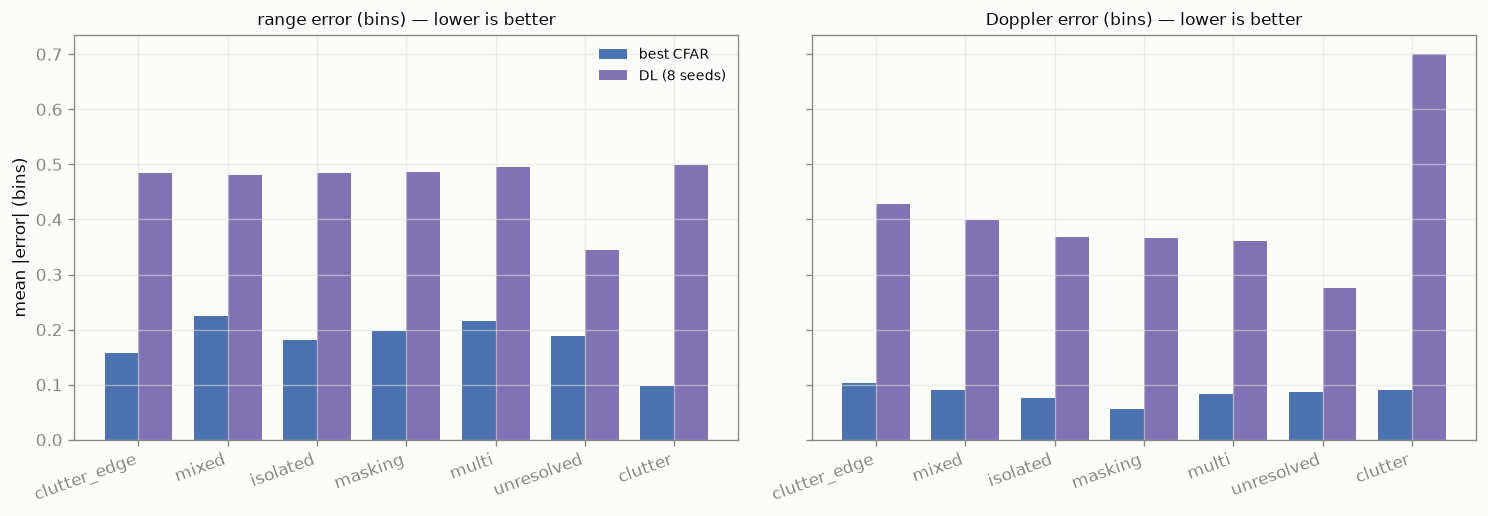

In [8]:
# Per condition, both axes. CFAR = the best method on that condition and that axis.
g1 = LOC[LOC.gate == 1]
rows = []
for c in CONDS:
    s = g1[g1.group == c].set_index("method")
    dl, cf = s.loc["DL"], s.drop("DL")
    rows.append(dict(condition=c, dl_range=dl.dr_bins, cfar_range=cf.dr_bins.min(),
                     range_x=dl.dr_bins / cf.dr_bins.min(),
                     dl_dopp=dl.dv_bins, cfar_dopp=cf.dv_bins.min(),
                     dopp_x=dl.dv_bins / cf.dv_bins.min()))
L = pd.DataFrame(rows).set_index("condition")
display(L.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
x = np.arange(len(CONDS)); w = 0.38
for ax, (a, b, t) in zip(axes, [("cfar_range", "dl_range", "range error"),
                                ("cfar_dopp", "dl_dopp", "Doppler error")]):
    ax.bar(x - w/2, L.loc[CONDS, a], w, color=CFARC, label="best CFAR")
    ax.bar(x + w/2, L.loc[CONDS, b], w, color=DLC, label="DL (8 seeds)")
    ax.set_xticks(x); ax.set_xticklabels(CONDS, rotation=20, ha="right")
    ax.set_title(f"{t} (bins) — lower is better", fontsize=10)
axes[0].set_ylabel("mean |error| (bins)"); axes[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

### CFAR wins on every condition, on both axes

Pooled at the ±1 gate: **Doppler 3.83×**, **range 2.40×**. Not a single condition where the network
places targets better.

**Why: the 3×3 label.** The network is trained that *all nine cells* around a target are "target".
Nothing in the loss rewards putting the peak on the centre cell rather than a corner one, so the
learned response is a blob and its maximum can sit anywhere inside it. CFAR has no such freedom —
it responds to the physical peak, which is sharp because the mainlobe is ~2 bins wide.

**Three independent pieces of evidence that the label is the cause, not the network:**

1. **It gets worse with training** (dev log §15–§16). Doppler error grows +0.220 bins from epoch 1
   to 25 — longer training teaches the label *shape*, not the target position.
2. **The gate-0 result** (§6): on exact-cell matching DL plateaus at **Pd 0.41** while CFAR reaches
   ~0.85. The network finds the target and then misses the cell.
3. **It is the network's only real weakness**, and it points at a fixable cause — a Gaussian or 1×1
   label — rather than at a capacity limit.

⚠️ **These ratios are inflated, and §9 explains by how much.** The denominator is a *minimum over
four methods per condition per axis*, and localization is conditioned on detection.

---
## 5 · Where they tie — and why the ties are not all the same

Two ties, for completely different reasons. One is a hard problem; the other is a physics ceiling
that no detector can pass.

In [9]:
t = pd.DataFrame({
    "gate ±1 diff": T1["diff"], "p (±1)": T1.p_boot, "sig ±1": T1["sig (Bonf)"],
    "gate ±3 diff": T2["diff"], "p (±3)": T2.p_boot, "sig ±3": T2["sig (Bonf)"],
    "CFAR Pd": T1.cfar_pd, "DL Pd": T1.dl_pd,
}).loc[["clutter", "unresolved"]]
display(t.round(4))
print("clutter: a tie at BOTH gates, and both methods detect under 20% of targets.")
print("unresolved: statistically significant at both gates, but see below -- it is not a win.")

,gate ±1 diff,p (±1),sig ±1,gate ±3 diff,p (±3),sig ±3,CFAR Pd,DL Pd
condition,,,,,,,,
clutter,-0.0023,0.793,False,-0.0193,0.068,False,0.1714,0.1691
unresolved,0.0119,0.001,True,0.0125,0.001,True,0.4638,0.4756


clutter: a tie at BOTH gates, and both methods detect under 20% of targets.
unresolved: statistically significant at both gates, but see below -- it is not a win.


### `clutter` — a genuine tie, and the hardest condition in the benchmark

CFAR 0.171, DL 0.169, p = 0.79. **Both methods miss ~83% of targets.** The clutter is
compound-Gaussian with a Weibull texture: spiky, heavy-tailed, and it violates the homogeneous
exponential assumption CFAR's threshold is derived from. Matching the *measured* Pfa forces the
threshold up so far that most targets fall under it.

The network does no better. It has the same 21×9 view and the same false-alarm budget, and nothing
in its training gives it a model of spiky clutter. **This is the honest limit of both approaches**
and the clearest place a stronger classical baseline (two-stage CFAR with per-region PDF estimation)
or a heavier-tailed-aware loss might matter.

### `unresolved` — significant, and **not a win**

+0.012 at p = 0.001. It clears Bonferroni comfortably. **It should still not be reported as a win.**

Two targets inside one mainlobe cannot be separated by *any* detector operating on this RD map — the
information is not there. One detection can match only one truth, so Pd is capped near **0.5** by
construction, and both methods sit essentially at that cap (CFAR 0.464, DL 0.476).

What the p-value is detecting is that 800 targets are enough to resolve a 1.2-percentage-point gap.
The gap is real; its *physical* meaning is nil. **This was pre-registered as an expected tie and it
came out significant** — a failed prediction, recorded as such in §9.

> A useful reminder in general: significance answers *is the difference real*, never *is the
> difference important*. Here the honest answer is yes and no respectively.

---
## 6 · Against theory — the one absolute check

Everything above is *relative*: one detector against another. This asks whether either is anywhere
near the physics, on `bench2_snr_sweep` (1,300 frames, one target each, SNR swept 0–24 dB, no
clutter, no interference).

The dashed line is a square-law detector that **knows** the noise level:
`Pd = Pfa^(1/(1+SNR))`. The gap below it is **CFAR loss** — the price of estimating that level from
a finite reference window.

In [10]:
s = SNRS.pivot(index="method", columns="gate", values=["snr50", "loss_db", "pd_max"])
display(s.round(3))
print("theory reaches Pd 0.5 at 10.89 dB.")
print("gate 0 = exact cell (the VALID comparison against theory).")
print("gate 1 = the project's operating point.")

snr50        loss_db        pd_max       
gate         0      1       0      1      0      1
method                                            
CA      11.365  9.124   0.470 -1.771  0.817  1.000
DL         NaN  8.050     NaN -2.845  0.415  0.999
GO      11.545  9.176   0.650 -1.719  0.831  1.000
OS      11.679  9.214   0.784 -1.681  0.817  1.000
SO      11.520  9.262   0.625 -1.632  0.859  1.000

theory reaches Pd 0.5 at 10.89 dB.
gate 0 = exact cell (the VALID comparison against theory).
gate 1 = the project's operating point.


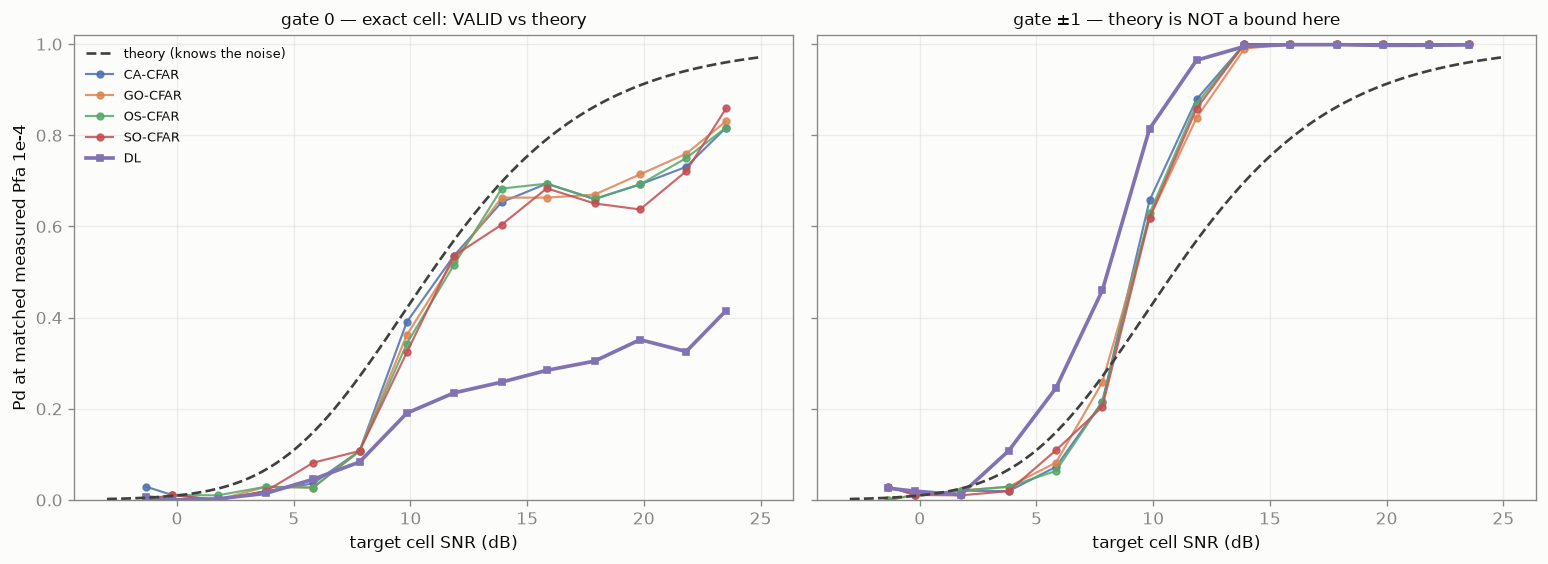

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
COLOR = {"CA": "#4c72b0", "GO": "#dd8452", "OS": "#55a868", "SO": "#c44e52", "DL": DLC}
sl = np.linspace(-3, 25, 300)
theory = 1e-4 ** (1.0 / (1.0 + 10 ** (sl / 10)))
for ax, gate in zip(axes, (0, 1)):
    ax.plot(sl, theory, "--", color="0.25", lw=1.6, zorder=5, label="theory (knows the noise)")
    for m in ("CA", "GO", "OS", "SO", "DL"):
        c = SNRC[(SNRC.gate == gate) & (SNRC.method == m)].sort_values("snr")
        ax.plot(c.snr, c.pd, "o-" if m != "DL" else "s-", ms=4,
                lw=2.2 if m == "DL" else 1.3, color=COLOR[m],
                alpha=1.0 if m == "DL" else 0.85, label=m if m == "DL" else f"{m}-CFAR")
    ax.set_xlabel("target cell SNR (dB)"); ax.set_ylim(0, 1.02)
    ax.set_title(("gate 0 — exact cell: VALID vs theory" if gate == 0
                  else "gate ±1 — theory is NOT a bound here"), fontsize=10)
axes[0].set_ylabel("Pd at matched measured Pfa 1e-4")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### Two findings, one of them a trap

**✅ CFAR loss is textbook: 0.47–0.78 dB.** At gate 0, CA needs 11.37 dB to reach Pd 0.5 against
theory's 10.89 dB. That is exactly the expected price of estimating the noise level rather than
knowing it. **The evaluation pipeline agrees with physics** — which is what this figure exists to
establish.

**⚠️ At the ±1 gate every method sits ABOVE theory.** All four CFAR variants *and* the network reach
Pd 0.5 some 1.7–2.8 dB *earlier* than theory says is possible. That is not five superior detectors —
theory is the probability that **one specific cell** crosses the threshold, while the ±1 gate counts
a hit anywhere in a **3×3** neighbourhood. Nine chances against one, and the mainlobe spans ~2 bins
so the neighbours carry real target energy.

**Theory is a bound only at gate 0.** The right-hand panel is included because it is the operating
point every other number in this notebook uses — but the dashed line there is a *reference shape*,
never a limit. A figure showing only that panel would claim five detectors beating physics.

**And the gate-0 panel states DL's weakness in the bluntest possible terms:** the network plateaus
at **Pd 0.41** even at 24 dB, where CFAR reaches ~0.85. It finds strong targets and still misses the
exact cell — the 3×3 label again, measured on a third split by a completely different route.

*(CFAR's own ~0.85 ceiling is not a detector failure either: labels sit on the true physical peak
only ~93% of the time (Milestone 22), so exact-cell matching cannot reach 1.0 for anybody.)*

---
## 7 · Computational cost

A detector that wins on Pd but cannot run in real time is not a useful result. Three measures,
because a single wall-clock number on one laptop is not portable.

In [12]:
r = RT.copy().set_index("method")
display(r.round(3))
dl_ms = float(r.loc["DL (TinyCNN)", "ms_per_frame"])
for m in r.index:
    if m == "DL (TinyCNN)":
        continue
    ratio = float(r.loc[m, "ms_per_frame"]) / dl_ms
    if ratio >= 1:
        print(f"  DL is {ratio:.2f}x FASTER than {m}")
    else:
        print(f"  DL is {1 / ratio:.2f}x slower than {m}")

,ms_per_frame,mac_per_cell,mmac_per_frame,params,vs_DL
method,,,,,
DL (TinyCNN),6.037,4896.0,80.216,5041,1.000
CA-CFAR,0.861,NaN,NaN,0,0.143
GO-CFAR,7.793,NaN,NaN,0,1.291
OS-CFAR,69.950,NaN,NaN,0,11.588
SO-CFAR,7.818,NaN,NaN,0,1.295


  DL is 7.01x slower than CA-CFAR
  DL is 1.29x FASTER than GO-CFAR
  DL is 11.59x FASTER than OS-CFAR
  DL is 1.30x FASTER than SO-CFAR


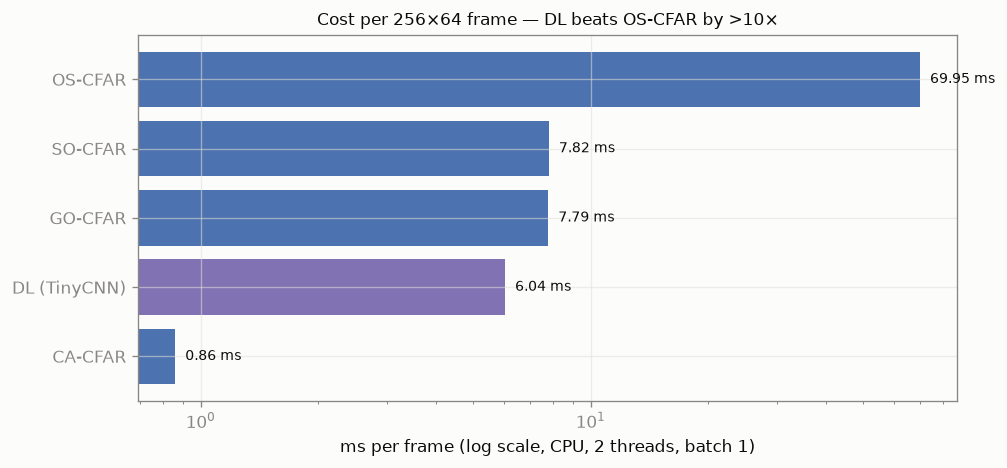

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.0))
o = RT.sort_values("ms_per_frame")
cols = [DLC if "DL" in m else CFARC for m in o.method]
ax.barh(o.method, o.ms_per_frame, color=cols)
for i, (m, v) in enumerate(zip(o.method, o.ms_per_frame)):
    ax.text(v * 1.06, i, f"{v:.2f} ms", va="center", fontsize=8.5)
ax.set_xscale("log"); ax.set_xlabel("ms per frame (log scale, CPU, 2 threads, batch 1)")
ax.set_title("Cost per 256×64 frame — DL beats OS-CFAR by >10×", fontsize=10)
plt.tight_layout(); plt.show()

### DL is cheap, but not because it is "one pass"

| | ms/frame | vs DL |
|---|---|---|
| CA-CFAR | 0.86 | DL is **7× slower** |
| **DL (TinyCNN)** | **6.04** | — |
| GO-CFAR | 7.79 | DL 1.3× faster |
| SO-CFAR | 7.82 | DL 1.3× faster |
| OS-CFAR | 69.95 | DL **11.6× faster** |

**The intuition that "the network does the whole map in one pass while CFAR works per cell" is
wrong for this project.** Our CFAR is fully vectorised with `scipy.ndimage`: `uniform_filter`
computes the box mean in **O(1) per cell** regardless of window size. TinyCNN does **4,896
multiply-accumulates per cell** — about three orders of magnitude *more* arithmetic than CA.

It still wins against OS because OS needs a **rank selection per cell**, which vectorises badly,
while the network's arithmetic is dense, regular and BLAS-friendly.

**Against GO/SO the ordering is within measurement noise** — DL measured *slower* than both on one
run and *faster* on another, so we do not claim it either way.

**The RadCNN comparison still stands and is the useful one:** RadCNN classifies one patch per cell
— a network invocation per cell — and reports ~10× OS-CFAR. Our fully-convolutional design shares
all overlapping computation and lands far below that. But that is an advantage over *other CNN
designs*, not over classical CFAR.

---
## 8 · Scorecard

In [14]:
loc1 = LOC[(LOC.gate == 1) & (LOC.group == "ALL")].set_index("method")
dlr, cfr = loc1.loc["DL"], loc1.drop("DL")
sc = pd.DataFrame([
    dict(question="Detection in clutter-edge interference", winner="DL",
         margin="+0.302 Pd (+68%)", confidence="p < 0.001, Bonferroni"),
    dict(question="Detection in multi-target interference", winner="DL",
         margin="+0.103 / +0.051 Pd (mixed / masking)", confidence="p < 0.001"),
    dict(question="Detection in homogeneous noise", winner="DL",
         margin="+0.058 Pd (isolated)", confidence="p < 0.001, but UNEXPLAINED (§9)"),
    dict(question="Detection in heavy-tailed clutter", winner="tie",
         margin="-0.002 Pd; both miss ~83%", confidence="p = 0.79"),
    dict(question="Detection of unresolved pairs", winner="neither",
         margin="+0.012 Pd at the ~0.5 physics cap", confidence="significant but meaningless (§9)"),
    dict(question="Range localization", winner="CFAR",
         margin=f"{dlr.dr_bins / cfr.dr_bins.min():.2f}x better", confidence="every condition"),
    dict(question="Doppler localization", winner="CFAR",
         margin=f"{dlr.dv_bins / cfr.dv_bins.min():.2f}x better", confidence="every condition"),
    dict(question="Agreement with theory (gate 0)", winner="CFAR",
         margin="0.47-0.78 dB loss; DL caps at Pd 0.41", confidence="bench2_snr_sweep"),
    dict(question="Speed vs OS-CFAR", winner="DL", margin="11.6x faster", confidence="same machine"),
    dict(question="Speed vs CA-CFAR", winner="CFAR", margin="7x faster than DL",
         confidence="same machine"),
    dict(question="Model size", winner="CFAR", margin="0 params vs 5,041", confidence="exact"),
])
display(sc)

,question,winner,margin,confidence
0,Detection in clutter-edge interference,DL,+0.302 Pd (+68%),"p < 0.001, Bonferroni"
1,Detection in multi-target interference,DL,+0.103 / +0.051 Pd (mixed / masking),p < 0.001
2,Detection in homogeneous noise,DL,+0.058 Pd (isolated),"p < 0.001, but UNEXPLAINED (§9)"
3,Detection in heavy-tailed clutter,tie,-0.002 Pd; both miss ~83%,p = 0.79
4,Detection of unresolved pairs,neither,+0.012 Pd at the ~0.5 physics cap,significant but meaningless (§9)
5,Range localization,CFAR,2.40x better,every condition
6,Doppler localization,CFAR,3.83x better,every condition
7,Agreement with theory (gate 0),CFAR,0.47-0.78 dB loss; DL caps at Pd 0.41,bench2_snr_sweep
8,Speed vs OS-CFAR,DL,11.6x faster,same machine
9,Speed vs CA-CFAR,CFAR,7x faster than DL,same machine


**Read the scorecard as three findings, not eleven rows:**

1. **Interference is where learning pays.** Every large DL win is a case where CFAR's reference
   window is contaminated — an edge, a second target, a ridge. That is a structural limitation of
   estimating noise from a local window, and it is exactly what a learned detector can route around.
2. **Precision is where the classical method pays.** CFAR responds to the physical peak; the network
   responds to a 3×3 training label. That is a *label* problem, not a capacity problem, and it is
   the most fixable thing in the project.
3. **Cost is a wash, in DL's favour against the expensive variant.** ~GO/SO cost, 11.6× cheaper than
   OS, 7× dearer than CA.

---
## 9 · Problems, caveats and odd results

**Read this before quoting anything above.** Every item is either a known bias with a known
direction, a result that is significant but not meaningful, or something we cannot explain.

### 9.1 The big one — DL loses nowhere, and that is a *weakness* in the result

The literature (`PROGRESS.md` Milestone 17) is clear that a credible learned detector normally loses
*somewhere* — a method that wins everywhere usually indicates a benchmark tilted in its favour
rather than a superior detector.

Ours loses nowhere on detection. Worse, we **had** a loss and lost it:

* On `bench2_val` at ±3, DL lost `clutter` by −0.043 at p = 0.005 — significant after correction.
* On `bench2_test` the same comparison is **−0.019, p = 0.068**: a tie, on **twice** the data.

That is retraction **C6** in the dev log. It was pre-registered as a predicted loss, so it is a
clean failed prediction rather than an argument — but the honest position is that **the only
condition where a classical method beat the network did not replicate.**

*Mitigating, slightly:* the two localization results and the gate-0 ceiling are real, large, and
reproduce on all three splits. DL does lose — just not on detection.

### 9.2 Three pre-registered predictions failed

Recorded because they were written down in advance (`docs/test_preregistration.md` §4):

| prediction | outcome |
|---|---|
| `clutter` at ±3 is a **loss** | **tie** (p = 0.068) — C6 above |
| `unresolved` is a **tie** | **significant win** (+0.012, p = 0.001) — but see §9.3 |
| **SO** stays the best classical method on range | **OS** takes it; SO best on only 2 of 7 conditions (was 5 of 7 on val) |

### 9.3 `unresolved` is statistically significant and physically meaningless

Two targets inside one mainlobe are not separable — Pd is capped near 0.5 because one detection can
match only one truth. Both methods sit at that cap. With 800 targets, a 1.2-point gap clears
Bonferroni. **Do not put `unresolved` in a list of wins.**

### 9.4 Both headline comparisons are biased, in opposite directions

* **Pd is biased AGAINST DL.** "Best CFAR" is a **maximum over four methods, chosen per condition**
  — a winner's-curse selection that inflates the classical arm. No deployed system gets to pick its
  CFAR variant per condition knowing the condition. Our reported wins are therefore *conservative*.
* **Localization is biased AGAINST DL too, and harder.** "Best CFAR" there is a **minimum over four
  methods, per condition AND per axis** — an envelope no single detector achieves.
* **But localization is also conditioned on detection**, which flatters whoever detects *less*. On
  `clutter` CFAR detects the strongest, cleanest targets, which are the easiest to place. The
  per-condition ratios in §4 — especially `clutter` — are therefore part precision gap and part
  selection effect. **The pooled 2.40× / 3.83× are the defensible numbers; the per-condition
  extremes are not.**
  *The clean fix, not run:* restrict both arms to targets *both* detect and recompute. It would be a
  new analysis invented after seeing the data, so it is logged as a limitation instead.

### 9.5 Neither gate is neutral

* **±1** — the gate region is *exactly* the 3×3 label block the network is trained on. The network
  is rewarded for hitting precisely what it was taught. It also penalises CFAR for label
  misalignment (~93%), since CFAR responds to the physical peak.
* **±3** — recovers those CFAR losses, but stops penalising placement altogether, converting DL's
  localization deficit into no penalty at all.

Both are reported for that reason. **±3 was not added after ±1 looked bad**: ±1 was primary from the
start, and ±3 is the gate where DL's `clutter` loss appeared, so it cannot be a gate chosen to
flatter the network.

### 9.6 `isolated` +0.058 is unexplained

Homogeneous noise is where CFAR is optimal and the corpus predicts a tie. On val it *was* a tie; on
test the margin tripled to a clear win. The pre-registration flagged it as uncertain in advance, so
it is not a post-hoc finding — but **we have no mechanism for it**, and an unexplained win in the
easiest condition is exactly the kind of result that later turns out to be an evaluation artefact.
Flagged, not explained.

### 9.7 Scope — this is sampling generalization only

`bench2_test` comes from the **same simulator with the same settings** as train and val — different
frames, different seed, no shared content, but not a different world. So this establishes that the
results hold on unseen *frames*. It is **not** evidence that anything survives a different clutter
model, a different sensor, or real measurements. One simulator, throughout.

### 9.8 Smaller things, kept on the record

* **`--threads` changes the trained weights** at fixed seed (max |Δw| 0.38 over 5,041 params) — same
  code, same seed, different floating-point reduction order. ~1 SE on localization, negligible on
  Pd. It is in the frozen config for that reason, and arms at different thread counts must not be
  pooled.
* **Localization degrades asymmetrically** between axes — Doppler +0.220 bins over epochs 1→25 and
  still climbing, range +0.147 and saturating by ~15. A *symmetric* 3×3 label predicts neither the
  differing timing nor the differing magnitude, so the label story is incomplete as stated
  (dev log Open/O4).
* **`clutter_edge` is 34% diluted** — only ~66% of its frames have a window that genuinely straddles
  the ridge. The margin survives on the true-edge subset, but the headline number is measured on the
  diluted stratum.
* **The bootstrap does not propagate threshold-selection variance.** Detections are taken at a
  threshold computed once per condition; re-deriving it inside every resample would cost ~200× the
  compute. The intervals are therefore mildly optimistic.
* **`os_rank_frac` was never swept** — OS-CFAR's one free parameter is at its default, so OS may be
  slightly under-tuned wherever it is the best classical method.

### 9.9 What would change the conclusions

Honest list of what we would do with more time, in order of how much it threatens the result:

1. **A stronger classical baseline** — two-stage CFAR with per-region PDF estimation, which is the
   right comparison on `clutter` and might well take that condition outright.
2. **A better label** — Gaussian or 1×1. It should collapse the localization gap, which is currently
   DL's only real weakness. If it does, DL wins everything, and §9.1 gets worse, not better.
3. **A second simulator or real data** (CARRADA) — the only thing that addresses §9.7.
4. **The CFAR→CNN ablation ladder** — decomposing the total margin into named relaxations, which
   would turn "DL wins on interference" into "*this specific* relaxation buys *this much*".

---
## Provenance

| | |
|---|---|
| split | `bench2_test`, 3,200 frames, read **once** on 19 Aug 2026 |
| protocol | `docs/test_preregistration.md`, committed 17 Aug, **before** the read |
| config | `configs/frozen_dl.yaml`, frozen 17 Aug |
| DL | `TinyCNN`, 5,041 params, RF 21×9, `pos_weight` 100, epoch 21, 8 seeds, threads 2 |
| CFAR | 21×9 window (guard 2/2, train 8/2), CA/GO/OS/SO |
| operating point | matched **measured** Pfa 1e-4, swept per condition |
| statistics | paired frame bootstrap, 2,000 resamples, Bonferroni across 7 conditions |
| full history | `notebooks/cnn_development_log.ipynb` (§1–20, Corrections C1–C6, Open O1–O4) |

Rebuild this notebook with `python scripts/build_comparison_notebook.py`.